In [1]:
import numpy as np
import pyvista as pv

from wakis import GridFIT3D


stl_file = "stl/012_LHC_WVM_6L2-316l.stl"

# Read solid
surf = pv.read(stl_file)
# surf = surf.decimate_pro(0.75)
# surf.save("stl/VSMIO_body_decimated.stl")
# Generate grid
Nx = 200
Ny = 200
Nz = 200
xmin, xmax, ymin, ymax, zmin, zmax = surf.bounds

grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids={"shell": stl_file},
    stl_materials={"shell": "stainless steel"},
    stl_method="voxelize_rectilinear",
    verbose=2,
)

Generating grid with 8000000 mesh cells...
    * Simulation domain bounds: 
                x:[-151.500, 101.500],
                y:[-110.150, 186.350],
                z:[7.000, 308.550]
    * Minimum cell sizes: dx=1.265e+00, dy=1.482e+00, dz=1.508e+00
Importing STL solids...


Converting polydata: 100%|██████████[00:07<00:00]
Generating binary mask: 100%|██████████[00:00<00:00]


    * STL solid shell: 551369 cells marked inside the solid.
Total grid initialization time: 13.946889162063599 s


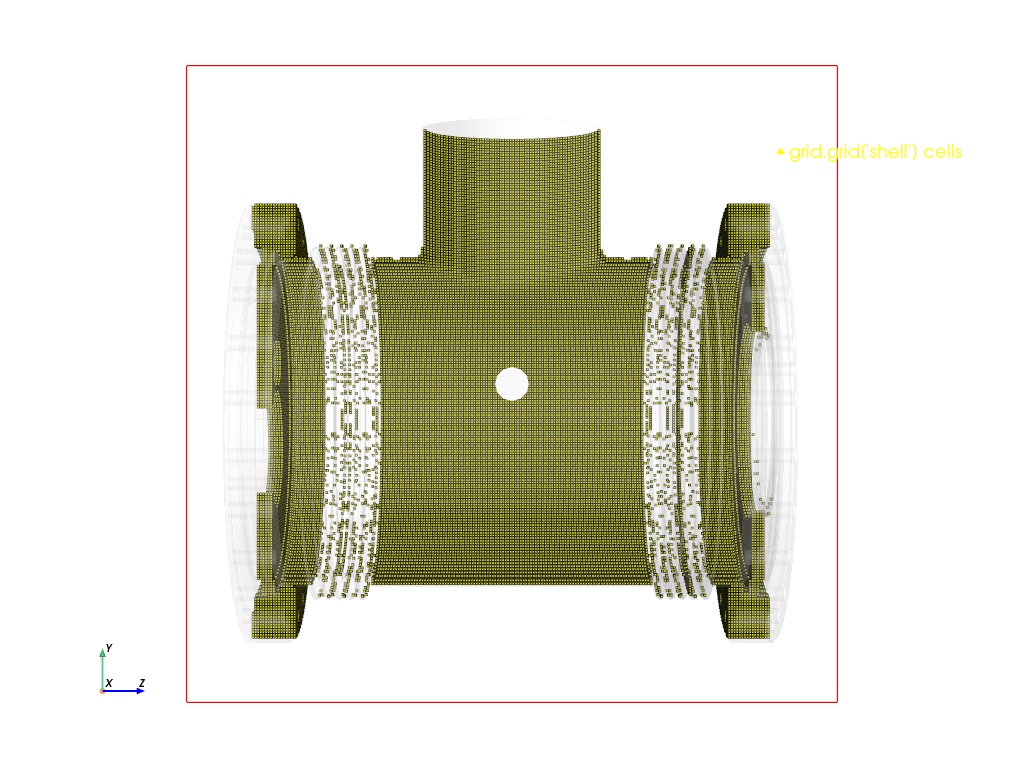

In [2]:
pv.set_jupyter_backend("static")

cells_inside = grid.grid.threshold(value=1, scalars="shell")
stl_surf = pv.read(stl_file)

pl = pv.Plotter()
pl.add_mesh(stl_surf, color="white", opacity=0.10, label="STL surface")
pl.add_mesh_clip_plane(
    cells_inside,
    color="yellow",
    show_edges=True,
    label="grid.grid['shell'] cells",
    normal="x",
    widget_color="white",
)
pl.camera_position = "zy"
pl.add_axes()
pl.add_legend()
pl.camera.zoom(1.5)
pl.enable_3_lights()
pl.show()

## SCS implementation
* We voxelize in a grid that has $factor \times$ resolution, --> subdivides each cell in subcells
* We compute the gradient to have an idea of boundaries and make the mask continuous (not sure if this step is needed)
* We add an extra step of gaussian blurring to make the material/mask changes smooth without loosing accuracy

and then we generate an accumulated mask by combining the $factor$ masks (e.g.) if $factor=4$ we sum 4 sub masks.

Finally, we clip the values to the maximum of int8 = 255. Each value that has 255 is fully inside the solid. Every cell that has value<255 is a partially filled cell with a volume fraction value/255.

In [3]:
from scipy.ndimage import gaussian_filter

factor = 4
Nx, Ny, Nz = grid.Nx * factor, grid.Ny * factor, grid.Nz * factor

dx = (xmax - xmin) / (Nx)
dy = (ymax - ymin) / (Ny)
dz = (zmax - zmin) / (Nz)

reference_vol = pv.ImageData(
    dimensions=(Nx, Ny, Nz),
    origin=(xmin + dx / 2, ymin + dy / 2, zmin + dz / 2),
    spacing=(dx, dy, dz),
)

surf = grid.read_stl("shell")
vox = surf.voxelize_rectilinear(reference_volume=reference_vol, progress_bar=True)
mask_ref = np.reshape(vox["mask"], (Nx, Ny, Nz), order="F")

# interpolate mask to grid Nx, Ny, Nz, computing gradient on each partial mask
dtype = np.int32
mask = np.zeros((grid.Nx, grid.Ny, grid.Nz)).astype(dtype)
for i in range(factor):
    partial = mask_ref[i::factor, i::factor, i::factor].astype(dtype) * 255 // 2
    grad = np.gradient(partial)
    partial += np.sqrt(grad[0] ** 2 + grad[1] ** 2 + grad[2] ** 2).astype(dtype)
    partial = gaussian_filter(partial, sigma=0.5).astype(dtype)
    mask += partial

mask = np.clip(mask, 0, 255) / 255
grid.grid["shell_2"] = np.reshape(mask, (grid.Nx * grid.Ny * grid.Nz))

Converting polydata: 100%|██████████[00:28<00:00]
Generating binary mask: 100%|██████████[00:00<00:00]


In [ ]:
del mask_ref, mask, grad, partial, reference_vol, vox

### Intermediate plots of each step

In [ ]:
import matplotlib.pyplot as plt

S = 255 // factor
ix = grid.Nx // 2  # middle YZ x-slice

fig, axes = plt.subplots(factor, 4, figsize=(18, 5 * factor))
fig.suptitle("PBA debug — YZ x-slice per iteration", fontsize=13)
col_titles = [
    "partial (scaled)",
    "grad magnitude",
    "gauss filtered (partial+grad)",
    "accumulated mask",
]

mask_d = np.zeros((grid.Nx, grid.Ny, grid.Nz), dtype=int)

for i in range(factor):
    # --- reproduce each intermediate matching main cell logic ---
    p0 = mask_ref[i::factor, i::factor, i::factor].astype(int) * S
    grad_d = np.gradient(p0.astype(float))
    grad_mag = np.sqrt(grad_d[0] ** 2 + grad_d[1] ** 2 + grad_d[2] ** 2).astype(int)
    p_filtered = gaussian_filter(p0 + grad_mag, sigma=1.0).astype(int)
    mask_d += p_filtered

    row = axes[i] if factor > 1 else axes
    slices = [
        p0[ix, :, :].T,
        grad_mag[ix, :, :].T,
        p_filtered[ix, :, :].T,
        mask_d[ix, :, :].T,
    ]
    cmaps = ["Blues", "hot", "viridis", "viridis"]

    for j, (data, cmap) in enumerate(zip(slices, cmaps)):
        im = row[j].imshow(data, origin="lower", cmap=cmap, aspect="auto")
        row[j].set_title(f"i={i}  {col_titles[j]}")
        row[j].set_xlabel("y")
        row[j].set_ylabel("z")
        plt.colorbar(im, ax=row[j], shrink=0.8)

plt.tight_layout()
plt.show()

print(f"S={S}, factor={factor}, ix={ix}")
print(
    f"p0 max: {p0.max()}, grad_mag max: {grad_mag.max()}, p_filtered max: {p_filtered.max()}, mask max: {mask_d.max()}"
)

### Plot of the final mask

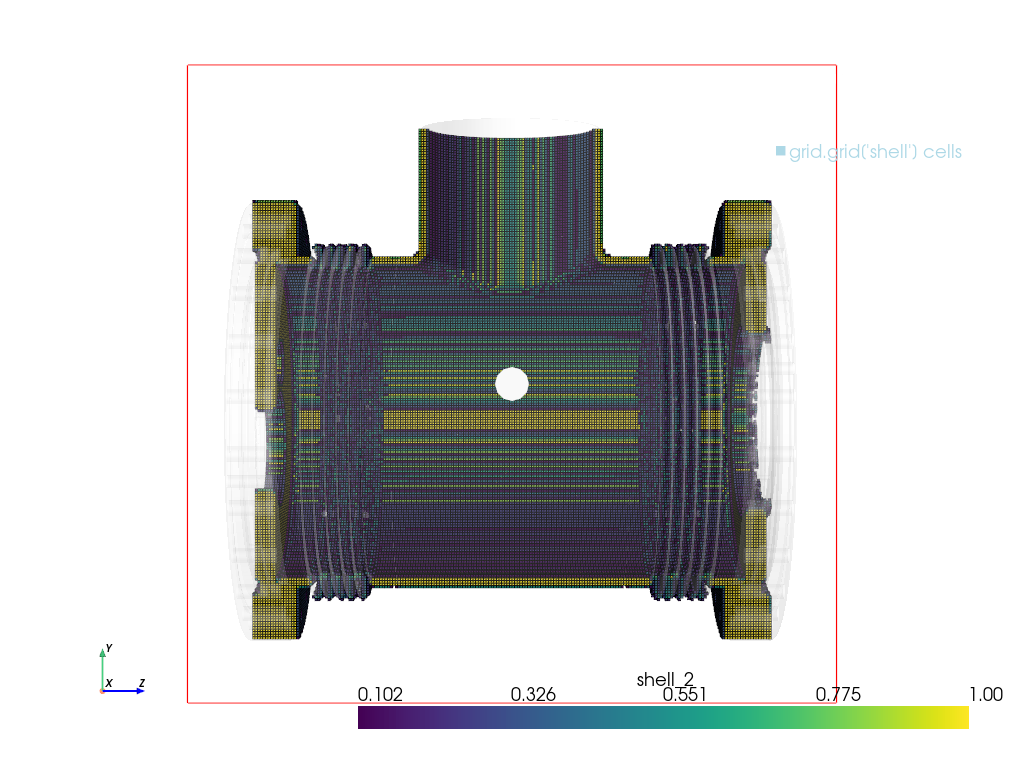

In [6]:
pv.set_jupyter_backend("static")

cells_inside = grid.grid.threshold(value=0.1, scalars="shell_2")
stl_surf = pv.read(stl_file)

pl = pv.Plotter()
pl.add_mesh(stl_surf, color="white", opacity=0.10, label="STL surface")
pl.add_mesh_clip_plane(
    cells_inside,
    scalars="shell_2",
    cmap="viridis",
    show_edges=True,
    label="grid.grid['shell'] cells",
    normal="x",
    widget_color="white",
)
pl.camera_position = "zy"
pl.add_axes()
pl.add_legend()
pl.camera.zoom(1.5)
pl.enable_3_lights()
pl.show()